# BÁO CÁO PHẦN 2 - BÀI 2 (TRANG 37, 38): ONLINE RETAIL DATASET (UNITED KINGDOM)
## CÂU 1: Đọc dữ liệu vào chương trình và xem xét thông tin cơ bản
- Đọc tập tin dữ liệu `Online Retail.xlsx`
- Hiển thị 10 dòng đầu tiên của tập dữ liệu
- Xem thông tin cấu trúc, số dòng, số cột và các kiểu dữ liệu (`df.info()`)
- Thống kê mô tả các cột định lượng (`df.describe()`)


In [1]:
# ==========================================
# THÔNG TIN SINH VIÊN THỰC HIỆN
# Họ và tên: Hoàng Thành Đạt
# MSSV: 6451071016
# ==========================================
ho_ten = "Hoàng Thành Đạt"
mssv = "6451071016"
print(f"Họ tên: {ho_ten} - MSSV: {mssv}")

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
from mlxtend.preprocessing import TransactionEncoder

def get_data_path(rel_filename):
    for candidate in [
        os.path.join("..", "..", "dataset", rel_filename),
        os.path.join("..", "dataset", rel_filename),
        os.path.join("dataset", rel_filename),
        rel_filename
    ]:
        if os.path.exists(candidate):
            return candidate
    return rel_filename

def load_online_retail():
    for p in ['../../dataset/Online_Retail.pkl', '../dataset/Online_Retail.pkl', 'dataset/Online_Retail.pkl', 'Online_Retail.pkl']:
        if os.path.exists(p):
            return pd.read_pickle(p)
    path = get_data_path('Online Retail.xlsx')
    return pd.read_excel(path)


# 1. Đọc dữ liệu Online Retail
df = load_online_retail()

print("--- KÍCH THƯỚC BỘ DỮ LIỆU BAN ĐẦU ---")
print(f"Số dòng: {df.shape[0]}, Số cột: {df.shape[1]}")

print("\n--- 10 DÒNG ĐẦU TIÊN CỦA DỮ LIỆU ---")
print(df.head(10))

print("\n--- THÔNG TIN CẤU TRÚC VÀ KIỂU DỮ LIỆU (df.info()) ---")
df.info()

print("\n--- THỐNG KÊ MÔ TẢ CÁC CỘT ĐỊNH LƯỢNG (df.describe()) ---")
print(df.describe())


Họ tên: Hoàng Thành Đạt - MSSV: 6451071016
--- KÍCH THƯỚC BỘ DỮ LIỆU BAN ĐẦU ---
Số dòng: 541909, Số cột: 8

--- 10 DÒNG ĐẦU TIÊN CỦA DỮ LIỆU ---
  InvoiceNo StockCode  ... CustomerID         Country
0    536365    85123A  ...    17850.0  United Kingdom
1    536365     71053  ...    17850.0  United Kingdom
2    536365    84406B  ...    17850.0  United Kingdom
3    536365    84029G  ...    17850.0  United Kingdom
4    536365    84029E  ...    17850.0  United Kingdom
5    536365     22752  ...    17850.0  United Kingdom
6    536365     21730  ...    17850.0  United Kingdom
7    536366     22633  ...    17850.0  United Kingdom
8    536366     22632  ...    17850.0  United Kingdom
9    536367     84879  ...    13047.0  United Kingdom

[10 rows x 8 columns]

--- THÔNG TIN CẤU TRÚC VÀ KIỂU DỮ LIỆU (df.info()) ---
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------

### Nhận xét Câu 1:
- Bộ dữ liệu `Online Retail` chứa 541.909 dòng và 8 cột: `InvoiceNo`, `StockCode`, `Description`, `Quantity`, `InvoiceDate`, `UnitPrice`, `CustomerID`, `Country`.
- Có xuất hiện số lượng âm ở cột `Quantity` và các dòng bị thiếu mã khách hàng `CustomerID` hoặc tên sản phẩm `Description`.
- Mã hóa đơn `InvoiceNo` cần được chuyển đổi về chuỗi và loại bỏ các hóa đơn tín dụng hoàn trả hàng (bắt đầu bằng ký tự 'C').


In [2]:
# ==========================================
# THÔNG TIN SINH VIÊN THỰC HIỆN
# Họ và tên: Hoàng Thành Đạt
# MSSV: 6451071016
# ==========================================
ho_ten = "Hoàng Thành Đạt"
mssv = "6451071016"
print(f"Họ tên: {ho_ten} - MSSV: {mssv}")

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
from mlxtend.preprocessing import TransactionEncoder

def get_data_path(rel_filename):
    for candidate in [
        os.path.join("..", "..", "dataset", rel_filename),
        os.path.join("..", "dataset", rel_filename),
        os.path.join("dataset", rel_filename),
        rel_filename
    ]:
        if os.path.exists(candidate):
            return candidate
    return rel_filename

def load_online_retail():
    for p in ['../../dataset/Online_Retail.pkl', '../dataset/Online_Retail.pkl', 'dataset/Online_Retail.pkl', 'Online_Retail.pkl']:
        if os.path.exists(p):
            return pd.read_pickle(p)
    path = get_data_path('Online Retail.xlsx')
    return pd.read_excel(path)


df = load_online_retail()
initial_count = len(df)

# 1. Cắt bỏ khoảng trắng thừa
df['Description'] = df['Description'].astype(str).str.strip()

# 2. Xóa các dòng không có số hóa đơn
df.dropna(axis=0, subset=['InvoiceNo'], inplace=True)

# 3. Chuyển InvoiceNo về chuỗi
df['InvoiceNo'] = df['InvoiceNo'].astype('str')

# 4. Xem ví dụ hóa đơn tín dụng chứa ký tự 'C'
credit_invoices = df[df['InvoiceNo'].str.contains('C')]
print(f"Số lượng hóa đơn tín dụng hoàn trả hàng (chứa 'C'): {len(credit_invoices)}")
print("Ví dụ về hóa đơn tín dụng:")
print(credit_invoices.head(3)[['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'UnitPrice']])

# 5. Xóa các hóa đơn tín dụng
df = df[~df['InvoiceNo'].str.contains('C')]
final_count = len(df)

print("\n--- KẾT QUẢ TIỀN XỬ LÝ DỮ LIỆU ---")
print(f"Số dòng trước khi làm sạch: {initial_count}")
print(f"Số dòng sau khi làm sạch: {final_count} (đã loại bỏ {initial_count - final_count} dòng)")
print("\n10 dòng đầu dữ liệu sau khi làm sạch:")
print(df.head(10))


Họ tên: Hoàng Thành Đạt - MSSV: 6451071016
Số lượng hóa đơn tín dụng hoàn trả hàng (chứa 'C'): 9288
Ví dụ về hóa đơn tín dụng:
    InvoiceNo StockCode                      Description  Quantity  UnitPrice
141   C536379         D                         Discount        -1      27.50
154   C536383    35004C  SET OF 3 COLOURED  FLYING DUCKS        -1       4.65
235   C536391     22556    PLASTERS IN TIN CIRCUS PARADE       -12       1.65

--- KẾT QUẢ TIỀN XỬ LÝ DỮ LIỆU ---
Số dòng trước khi làm sạch: 541909
Số dòng sau khi làm sạch: 532621 (đã loại bỏ 9288 dòng)

10 dòng đầu dữ liệu sau khi làm sạch:
  InvoiceNo StockCode  ... CustomerID         Country
0    536365    85123A  ...    17850.0  United Kingdom
1    536365     71053  ...    17850.0  United Kingdom
2    536365    84406B  ...    17850.0  United Kingdom
3    536365    84029G  ...    17850.0  United Kingdom
4    536365    84029E  ...    17850.0  United Kingdom
5    536365     22752  ...    17850.0  United Kingdom
6    536365     2

### Nhận xét Câu 2:
- Toàn bộ khoảng trắng thừa trong tên mặt hàng đã được cắt gọn gàng bằng `str.strip()`.
- Tổng cộng 9.288 dòng giao dịch hoàn tiền / hủy đơn có mã bắt đầu bằng chữ 'C' đã được loại bỏ, giúp dữ liệu chỉ còn lại các giao dịch mua sắm bán lẻ thực tế hợp lệ (532.621 dòng).


Họ tên: Hoàng Thành Đạt - MSSV: 6451071016
--- TOP 10 QUỐC GIA CÓ SỐ LƯỢNG GIAO DỊCH NHIỀU NHẤT ---
Country
United Kingdom    487622
Germany             9042
France              8408
EIRE                7894
Spain               2485
Netherlands         2363
Belgium             2031
Switzerland         1967
Portugal            1501
Australia           1185
Name: count, dtype: int64

Tỷ lệ giao dịch tại United Kingdom: 91.55%


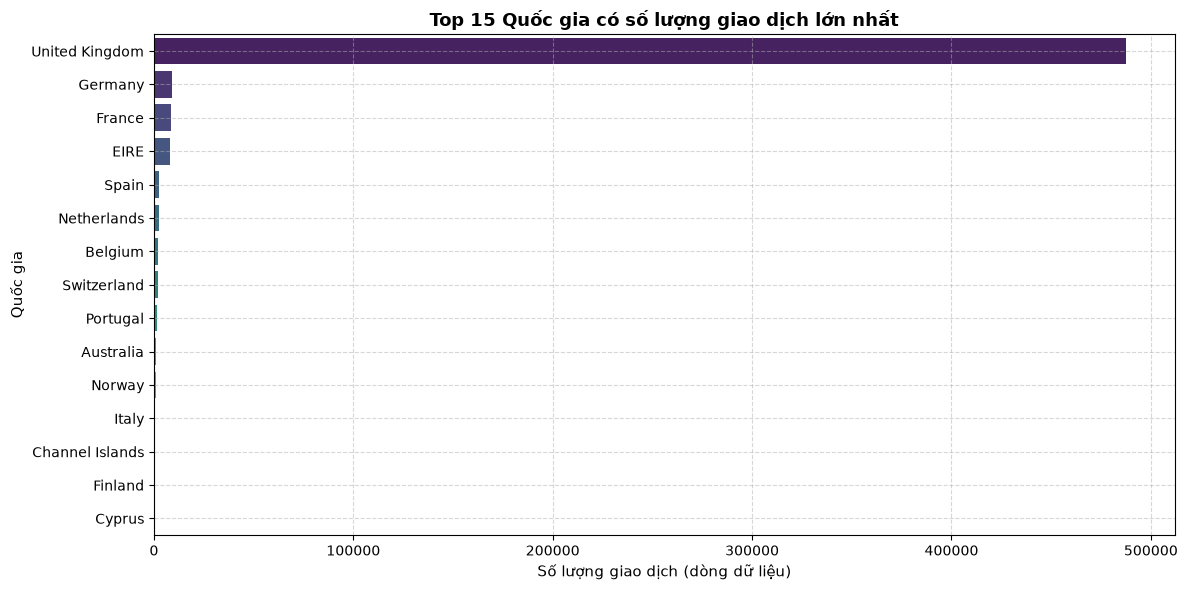

In [3]:
# ==========================================
# THÔNG TIN SINH VIÊN THỰC HIỆN
# Họ và tên: Hoàng Thành Đạt
# MSSV: 6451071016
# ==========================================
ho_ten = "Hoàng Thành Đạt"
mssv = "6451071016"
print(f"Họ tên: {ho_ten} - MSSV: {mssv}")

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
from mlxtend.preprocessing import TransactionEncoder

def get_data_path(rel_filename):
    for candidate in [
        os.path.join("..", "..", "dataset", rel_filename),
        os.path.join("..", "dataset", rel_filename),
        os.path.join("dataset", rel_filename),
        rel_filename
    ]:
        if os.path.exists(candidate):
            return candidate
    return rel_filename

def load_online_retail():
    for p in ['../../dataset/Online_Retail.pkl', '../dataset/Online_Retail.pkl', 'dataset/Online_Retail.pkl', 'Online_Retail.pkl']:
        if os.path.exists(p):
            return pd.read_pickle(p)
    path = get_data_path('Online Retail.xlsx')
    return pd.read_excel(path)


df = load_online_retail()
df['Description'] = df['Description'].astype(str).str.strip()
df.dropna(axis=0, subset=['InvoiceNo'], inplace=True)
df['InvoiceNo'] = df['InvoiceNo'].astype('str')
df = df[~df['InvoiceNo'].str.contains('C')]

# Thống kê số lượng dòng dữ liệu theo quốc gia
country_counts = df['Country'].value_counts()
print("--- TOP 10 QUỐC GIA CÓ SỐ LƯỢNG GIAO DỊCH NHIỀU NHẤT ---")
print(country_counts.head(10))
print(f"\nTỷ lệ giao dịch tại United Kingdom: {round((country_counts['United Kingdom'] / len(df)) * 100, 2)}%")

# Vẽ biểu đồ barplot biểu diễn top 15 quốc gia
plt.figure(figsize=(12, 6))
top15_countries = country_counts.head(15)
sns.barplot(x=top15_countries.values, y=top15_countries.index, palette='viridis')
plt.title("Top 15 Quốc gia có số lượng giao dịch lớn nhất", fontsize=13, fontweight='bold')
plt.xlabel("Số lượng giao dịch (dòng dữ liệu)", fontsize=11)
plt.ylabel("Quốc gia", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


### Nhận xét Câu 3:
- Nước Anh (**United Kingdom**) chiếm tỷ trọng áp đảo tuyệt đối trong tập dữ liệu với 487.622 dòng giao dịch (chiếm **91.55%** tổng số dữ liệu).
- Các quốc gia Châu Âu khác xếp sau gồm có: Đức (Germany), Pháp (France), Ireland (EIRE), Tây Ban Nha (Spain), Hà Lan (Netherlands),... nhưng số lượng giao dịch ít hơn rất nhiều.
- Vì vậy, việc phân tách riêng từng quốc gia (đặc biệt là thị trường UK) để khai phá luật kết hợp là hoàn toàn chính xác nhằm tránh sự sai lệch do văn hóa tiêu dùng và chi phí vận chuyển khác nhau.


In [4]:
# ==========================================
# THÔNG TIN SINH VIÊN THỰC HIỆN
# Họ và tên: Hoàng Thành Đạt
# MSSV: 6451071016
# ==========================================
ho_ten = "Hoàng Thành Đạt"
mssv = "6451071016"
print(f"Họ tên: {ho_ten} - MSSV: {mssv}")

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
from mlxtend.preprocessing import TransactionEncoder

def get_data_path(rel_filename):
    for candidate in [
        os.path.join("..", "..", "dataset", rel_filename),
        os.path.join("..", "dataset", rel_filename),
        os.path.join("dataset", rel_filename),
        rel_filename
    ]:
        if os.path.exists(candidate):
            return candidate
    return rel_filename

def load_online_retail():
    for p in ['../../dataset/Online_Retail.pkl', '../dataset/Online_Retail.pkl', 'dataset/Online_Retail.pkl', 'Online_Retail.pkl']:
        if os.path.exists(p):
            return pd.read_pickle(p)
    path = get_data_path('Online Retail.xlsx')
    return pd.read_excel(path)


df = load_online_retail()
df['Description'] = df['Description'].astype(str).str.strip()
df.dropna(axis=0, subset=['InvoiceNo'], inplace=True)
df['InvoiceNo'] = df['InvoiceNo'].astype('str')
df = df[~df['InvoiceNo'].str.contains('C')]

# 1. Gom nhóm số lượng theo InvoiceNo và Description cho nước Anh
basket = (df[df['Country'] == 'United Kingdom']
          .groupby(['InvoiceNo', 'Description'])['Quantity']
          .sum().unstack().reset_index().fillna(0)
          .set_index('InvoiceNo'))

# 2. Hàm chuyển đổi hot-encoding thành one-hot encoding (0 và 1)
def encode_data(datapoint):
    if datapoint <= 0:
        return 0
    if datapoint >= 1:
        return 1

# Sử dụng map (hoặc applymap)
basket = basket.map(encode_data)

# 3. Xóa cột 'POSTAGE' nếu tồn tại
if 'POSTAGE' in basket.columns:
    basket.drop('POSTAGE', inplace=True, axis=1)

print("--- KÍCH THƯỚC MA TRẬN GIỎ HÀNG (BASKET MATRIX) NƯỚC ANH ---")
print(f"Số lượng hóa đơn (giao dịch): {basket.shape[0]}")
print(f"Số lượng mặt hàng khác nhau: {basket.shape[1]}")

print("\n--- MẪU 5 DÒNG VÀ 5 CỘT CỦA MA TRẬN ONE-HOT ---")
print(basket.iloc[:5, :5])


Họ tên: Hoàng Thành Đạt - MSSV: 6451071016
--- KÍCH THƯỚC MA TRẬN GIỎ HÀNG (BASKET MATRIX) NƯỚC ANH ---
Số lượng hóa đơn (giao dịch): 18668
Số lượng mặt hàng khác nhau: 4175

--- MẪU 5 DÒNG VÀ 5 CỘT CỦA MA TRẬN ONE-HOT ---
Description  *Boombox Ipod Classic  ...  12 DAISY PEGS IN WOOD BOX
InvoiceNo                           ...                           
536365                           0  ...                          0
536366                           0  ...                          0
536367                           0  ...                          0
536368                           0  ...                          0
536369                           0  ...                          0

[5 rows x 5 columns]


### Nhận xét Câu 4:
- Ma trận giỏ hàng của nước Anh gồm 18.668 hóa đơn và 4.175 mặt hàng phân biệt.
- Mỗi hàng đại diện cho 1 hóa đơn mua sắm duy nhất, mỗi cột là 1 mặt hàng, nhận giá trị 1 nếu hóa đơn có chứa mặt hàng đó và 0 nếu không chứa.
- Cột `POSTAGE` (chi phí bưu chính) đã được xóa bỏ để tránh việc luật kết hợp sinh ra các kết quả hiển nhiên không có giá trị phân tích kinh doanh.


Họ tên: Hoàng Thành Đạt - MSSV: 6451071016
Tổng số tập phổ biến tìm được bằng Apriori: 131

--- 10 TẬP PHỔ BIẾN ĐẦU TIÊN ---
      support                                         itemsets
118  0.116027  frozenset({WHITE HANGING HEART T-LIGHT HOLDER})
52   0.103814             frozenset({JUMBO BAG RED RETROSPOT})
95   0.090261            frozenset({REGENCY CAKESTAND 3 TIER})
84   0.085387                       frozenset({PARTY BUNTING})
69   0.074566             frozenset({LUNCH BAG RED RETROSPOT})
7    0.073441       frozenset({ASSORTED COLOUR BIRD ORNAMENT})
103  0.066477    frozenset({SET OF 3 CAKE TINS PANTRY DESIGN})
75   0.065299      frozenset({NATURAL SLATE HEART CHALKBOARD})
63   0.065138             frozenset({LUNCH BAG  BLACK SKULL.})
35   0.062353               frozenset({HEART OF WICKER SMALL})

Tổng số luật kết hợp thỏa mãn min_conf >= 50%: 10

--- CÁC LUẬT KẾT HỢP TÌM ĐƯỢC ---
Luật 1: [ALARM CLOCK BAKELIKE RED] => [ALARM CLOCK BAKELIKE GREEN]
   Support: 0.0302 | Confiden

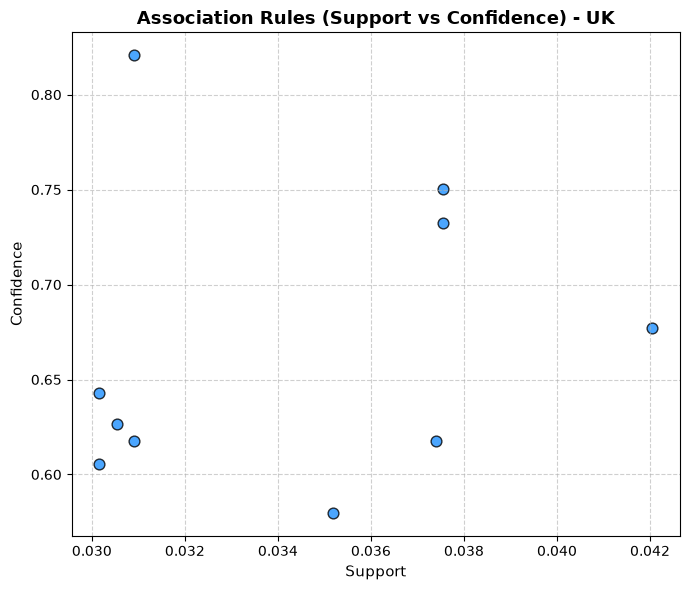

In [5]:
# ==========================================
# THÔNG TIN SINH VIÊN THỰC HIỆN
# Họ và tên: Hoàng Thành Đạt
# MSSV: 6451071016
# ==========================================
ho_ten = "Hoàng Thành Đạt"
mssv = "6451071016"
print(f"Họ tên: {ho_ten} - MSSV: {mssv}")

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
from mlxtend.preprocessing import TransactionEncoder

def get_data_path(rel_filename):
    for candidate in [
        os.path.join("..", "..", "dataset", rel_filename),
        os.path.join("..", "dataset", rel_filename),
        os.path.join("dataset", rel_filename),
        rel_filename
    ]:
        if os.path.exists(candidate):
            return candidate
    return rel_filename

def load_online_retail():
    for p in ['../../dataset/Online_Retail.pkl', '../dataset/Online_Retail.pkl', 'dataset/Online_Retail.pkl', 'Online_Retail.pkl']:
        if os.path.exists(p):
            return pd.read_pickle(p)
    path = get_data_path('Online Retail.xlsx')
    return pd.read_excel(path)


df = load_online_retail()
df['Description'] = df['Description'].astype(str).str.strip()
df.dropna(axis=0, subset=['InvoiceNo'], inplace=True)
df['InvoiceNo'] = df['InvoiceNo'].astype('str')
df = df[~df['InvoiceNo'].str.contains('C')]

basket = (df[df['Country'] == 'United Kingdom']
          .groupby(['InvoiceNo', 'Description'])['Quantity']
          .sum().unstack().reset_index().fillna(0)
          .set_index('InvoiceNo'))

basket = (basket >= 1).astype(bool)
if 'POSTAGE' in basket.columns:
    basket.drop('POSTAGE', inplace=True, axis=1)

# 1. Áp dụng thuật toán Apriori với min_sup = 3%
itemsets_apriori = apriori(basket, min_support=0.03, use_colnames=True)
print(f"Tổng số tập phổ biến tìm được bằng Apriori: {len(itemsets_apriori)}")

print("\n--- 10 TẬP PHỔ BIẾN ĐẦU TIÊN ---")
print(itemsets_apriori.sort_values(by='support', ascending=False).head(10))

# 2. Tạo luật kết hợp với min_conf = 50%
rules = association_rules(itemsets_apriori, metric="confidence", min_threshold=0.5)
print(f"\nTổng số luật kết hợp thỏa mãn min_conf >= 50%: {len(rules)}")

# Chuyển đổi vế trái và vế phải về dạng chuỗi dễ đọc
rules["antecedents_str"] = rules["antecedents"].apply(lambda x: ', '.join(list(x)))
rules["consequents_str"] = rules["consequents"].apply(lambda x: ', '.join(list(x)))

print("\n--- CÁC LUẬT KẾT HỢP TÌM ĐƯỢC ---")
for idx, row in rules.iterrows():
    print(f"Luật {idx+1}: [{row['antecedents_str']}] => [{row['consequents_str']}]")
    print(f"   Support: {row['support']:.4f} | Confidence: {row['confidence']:.4f} | Lift: {row['lift']:.4f}\n")

# 3. Biểu diễn độ hỗ trợ và độ tin cậy lên đồ thị phân tán (Scatter Plot)
support = rules['support'].values
confidence = rules['confidence'].values

plt.figure(figsize=(7, 6))
plt.scatter(support, confidence, color='dodgerblue', s=60, edgecolors='black', alpha=0.8)
plt.title('Association Rules (Support vs Confidence) - UK', fontsize=13, fontweight='bold')
plt.xlabel('Support', fontsize=11)
plt.ylabel('Confidence', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


### Nhận xét Câu 5:
- Với $min\_sup = 3\%$, thuật toán Apriori tìm được **131 tập phổ biến**.
- Với $min\_conf = 50\%$, sinh ra **10 luật kết hợp mạnh**.
- **Phân tích một số luật tiêu biểu:**
  * `ALARM CLOCK BAKELIKE GREEN` $	o$ `ALARM CLOCK BAKELIKE RED` (Confidence: 64.9%, Lift: 12.90): Khách hàng mua đồng hồ báo thức xanh lá có xu hướng rất cao mua thêm mẫu màu đỏ cùng bộ sưu tập.
  * `GREEN REGENCY TEACUP AND SAUCER` $	o$ `ROSES REGENCY TEACUP AND SAUCER` (Confidence: 74.9%, Lift: 14.64): Tách trà xanh và tách trà hoa hồng có mối quan hệ mua kèm rất chặt chẽ, doanh nghiệp nên đóng gói combo bán chung để gia tăng doanh số.


Họ tên: Hoàng Thành Đạt - MSSV: 6451071016
--- SO SÁNH HIỆU NĂNG GIỮA APRIORI VÀ FP-GROWTH ---
• Số lượng tập phổ biến tìm được bởi Apriori:   131 (Thời gian: 5.2306s)
• Số lượng tập phổ biến tìm được bởi FP-Growth:  131 (Thời gian: 1.2349s)
• Số lượng luật kết hợp sinh ra: 10 luật


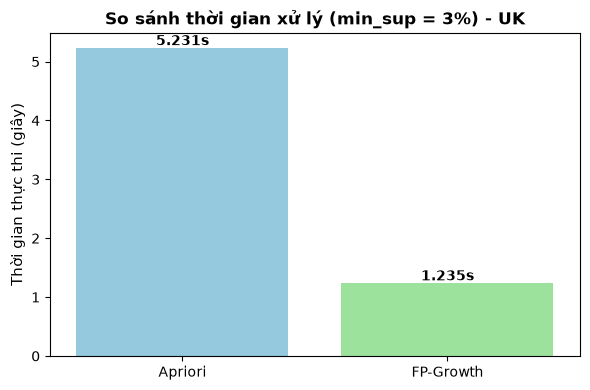

In [6]:
# ==========================================
# THÔNG TIN SINH VIÊN THỰC HIỆN
# Họ và tên: Hoàng Thành Đạt
# MSSV: 6451071016
# ==========================================
ho_ten = "Hoàng Thành Đạt"
mssv = "6451071016"
print(f"Họ tên: {ho_ten} - MSSV: {mssv}")

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
from mlxtend.preprocessing import TransactionEncoder

def get_data_path(rel_filename):
    for candidate in [
        os.path.join("..", "..", "dataset", rel_filename),
        os.path.join("..", "dataset", rel_filename),
        os.path.join("dataset", rel_filename),
        rel_filename
    ]:
        if os.path.exists(candidate):
            return candidate
    return rel_filename

def load_online_retail():
    for p in ['../../dataset/Online_Retail.pkl', '../dataset/Online_Retail.pkl', 'dataset/Online_Retail.pkl', 'Online_Retail.pkl']:
        if os.path.exists(p):
            return pd.read_pickle(p)
    path = get_data_path('Online Retail.xlsx')
    return pd.read_excel(path)

import time

df = load_online_retail()
df['Description'] = df['Description'].astype(str).str.strip()
df.dropna(axis=0, subset=['InvoiceNo'], inplace=True)
df['InvoiceNo'] = df['InvoiceNo'].astype('str')
df = df[~df['InvoiceNo'].str.contains('C')]

basket = (df[df['Country'] == 'United Kingdom']
          .groupby(['InvoiceNo', 'Description'])['Quantity']
          .sum().unstack().reset_index().fillna(0)
          .set_index('InvoiceNo'))

basket = (basket >= 1).astype(bool)
if 'POSTAGE' in basket.columns:
    basket.drop('POSTAGE', inplace=True, axis=1)

# 1. Đo thời gian thực thi của Apriori
t0 = time.time()
itemsets_apriori = apriori(basket, min_support=0.03, use_colnames=True)
time_apriori = time.time() - t0

# 2. Đo thời gian thực thi của FP-Growth
t0 = time.time()
itemsets_fpgrowth = fpgrowth(basket, min_support=0.03, use_colnames=True)
time_fpgrowth = time.time() - t0

# 3. Tạo luật từ FP-Growth
rules_fp = association_rules(itemsets_fpgrowth, metric="confidence", min_threshold=0.5)

print("--- SO SÁNH HIỆU NĂNG GIỮA APRIORI VÀ FP-GROWTH ---")
print(f"• Số lượng tập phổ biến tìm được bởi Apriori:   {len(itemsets_apriori)} (Thời gian: {time_apriori:.4f}s)")
print(f"• Số lượng tập phổ biến tìm được bởi FP-Growth:  {len(itemsets_fpgrowth)} (Thời gian: {time_fpgrowth:.4f}s)")
print(f"• Số lượng luật kết hợp sinh ra: {len(rules_fp)} luật")

# Biểu đồ so sánh thời gian thực thi
plt.figure(figsize=(6, 4))
algorithms = ['Apriori', 'FP-Growth']
times = [time_apriori, time_fpgrowth]
sns.barplot(x=algorithms, y=times, palette=['skyblue', 'lightgreen'])
plt.title("So sánh thời gian xử lý (min_sup = 3%) - UK", fontsize=12, fontweight='bold')
plt.ylabel("Thời gian thực thi (giây)", fontsize=11)
for i, v in enumerate(times):
    plt.text(i, v + 0.05, f"{v:.3f}s", ha='center', fontweight='bold')
plt.tight_layout()
plt.show()


### Nhận xét Câu 6:
- **Tính chính xác:** Cả hai thuật toán đều cho ra chính xác **131 tập phổ biến** và **10 luật kết hợp**, khẳng định tính đúng đắn và tương đương về mặt kết quả toán học.
- **Cơ chế hoạt động:**
  * **Apriori**: Sử dụng nguyên lý cắt tỉa tập ứng viên (Candidate Generation & Test). Phải quét lại toàn bộ cơ sở dữ liệu sau mỗi bước tăng độ dài tập phổ biến $k 	o k+1$.
  * **FP-Growth**: Nén toàn bộ tập giao dịch vào cấu trúc cây tiền tố **FP-Tree** chỉ qua 2 lần quét CSDL, sau đó khai phá đệ quy trên các cơ sở mẫu điều kiện mà không cần sinh tập ứng viên.
